# Исследование данных о ценах в новостройках

## 1. Загрузка и первичная проверка данных

Используем два набора: исходные объявления и объявления, собранные
из каталогов ГК ФСК. Сначала сравним столбцы и типы данных.

In [1]:
from pathlib import Path

import pandas as pd

import matplotlib.pyplot as plt

In [2]:
data_dir = Path("data") if Path("data").is_dir() else Path("../data")

original_path = next((data_dir / "raw").rglob("newbuild_prices.csv"))
id_types = {"building": "string", "listing_number": "string"}

original = pd.read_csv(original_path, dtype=id_types)
collected = pd.read_csv(
    data_dir / "collected" / "newbuild_prices_fsk_projects.csv",
    dtype=id_types,
)

print(f"Исходные объявления: {len(original)}")
print(f"Собранные объявления: {len(collected)}")

Исходные объявления: 804
Собранные объявления: 39


In [3]:
schema = pd.DataFrame({
    "Исходный CSV": original.dtypes.astype(str),
    "Собранный CSV": collected.dtypes.astype(str),
}).fillna("нет столбца")

differences = schema[schema["Исходный CSV"] != schema["Собранный CSV"]]

if differences.empty:
    print("Столбцы и типы совпадают.")
else:
    display(differences)

,Исходный CSV,Собранный CSV
section,float64,int64
floors_total,float64,int64
finish,str,float64
handover_text,str,float64
original_price_rub,float64,int64
discount_pct,float64,int64
source_crawled_age,str,float64


Различия типов не требуют исправления перед объединением данных.

Добавим `data_origin`, чтобы при анализе отличать исходные объявления
от собранных. Затем сверим названия ЖК ГК ФСК и их `project_group`
в обоих наборах. Эта группа понадобится при разбиении на обучение и тест.

In [4]:
df = pd.concat(
    [
        original.assign(data_origin="original"),
        collected.assign(data_origin="collected_fsk"),
    ],
    ignore_index=True,
)

df.groupby("data_origin").size().rename("Число объявлений")

data_origin
collected_fsk     39
original         804
Name: Число объявлений, dtype: int64

In [5]:
fsk_projects = (
    df.loc[
        df["developer"].str.contains("ФСК", case=False, na=False),
        ["project", "project_group", "data_origin"],
    ]
    .drop_duplicates()
    .sort_values(["project", "data_origin"])
    .reset_index(drop=True)
)

fsk_projects

,project,project_group,data_origin
0,Амбер Сити,ГК ФСК | Амбер Сити,original
1,Архитектор,ГК ФСК | Архитектор,collected_fsk
2,Датский квартал,ГК ФСК | Датский квартал,original
3,Движение. Говорово,ГК ФСК | Движение. Говорово,original
4,Лэйк,ГК ФСК | Лэйк,original
5,Режиссер,ГК ФСК | Режиссер,original
6,Римский,ГК ФСК | Римский,original
7,Роттердам,ГК ФСК | Роттердам,original
8,Сидней Сити,ГК ФСК | Сидней Сити,original
9,Симоновский Вал,ГК ФСК | Симоновский Вал,collected_fsk


Переименовывать ЖК не нужно.

Зафиксируем распределение количества объявлений в разрезе ЖК, затем выведем основные статистики данных.

In [6]:
df['project'].value_counts().to_frame()

,count
project,
Левел Южнопортовая,244
Скай Гарден,109
"Левел Звенигородская,этап 1",43
Витебский парк,39
Левел Лесной,30
Матвеевский парк,28
Янинский лес,28
Амбер Сити,24
Саларьево парк,22


In [7]:
display(df.select_dtypes('number').describe().round(2).T)
df.select_dtypes('str').describe().round(2).T

,count,mean,std,min,25%,50%,75%,max
section,224.0,3.19,3.02,1.0,1.0,3.0,4.00,20.0
rooms,843.0,1.65,1.05,0.0,1.0,2.0,2.00,4.0
area_m2,843.0,50.59,20.00,16.9,34.9,45.3,62.75,135.8
floor,843.0,22.23,16.56,1.0,8.0,18.0,35.00,67.0
floors_total,653.0,36.95,21.41,7.0,15.0,37.0,49.00,69.0
asking_price_rub,843.0,23438021.52,9824560.72,4167460.0,17520964.5,21144007.0,28294306.00,96403198.0
asking_price_per_m2_rub,843.0,480252.14,139913.02,159700.0,383900.0,484528.0,557875.00,952005.0
original_price_rub,629.0,34161856.06,13141426.35,12485370.0,25777379.0,29807400.0,40547580.00,105937580.0
discount_pct,629.0,27.37,10.55,3.0,19.3,35.0,35.00,38.3


,count,unique,top,freq
record_id,843,843,FSK-00001,1
developer,843,3,Level Group,405
project,843,42,Левел Южнопортовая,244
project_group,843,42,Level Group | Левел Южнопортовая,244
building,843,60,10,132
listing_number,650,630,666,2
id_quality,843,2,source_listing_id,650
price_per_m2_kind,843,2,published,438
source_kind,843,2,catalog_page,822
source_url,843,135,https://level.ru/filter/1k-kvartiry-level/page21/,58


В объединённой выборке 843 объявления из 42 ЖК. Комплексы представлены
неравномерно: на «Левел Южнопортовую» приходится 244 объявления
(около 29% выборки).

Судя по статистикам (mean, std, квартили), выбросов в данных практически нет.

## 2. Дубликаты и пропуски

Проверим полные повторы без учёта технического ID и происхождения строки.
Отдельно найдём повторяющиеся номера квартир в одном ЖК и корпусе,
если номер получен из источника. Такие совпадения сначала проверим,
а не будем автоматически удалять.

Затем сравним пропуски по наборам и застройщикам. Комнатность `0`
означает студию, а пустое поле `finish` - что отделка не указана.

In [8]:
content_columns = df.columns.drop(["record_id", "data_origin"])
exact_duplicates = df.duplicated(subset=content_columns, keep=False)

print(f"Строк в группах полных повторов: {exact_duplicates.sum()}")

Строк в группах полных повторов: 0


In [9]:
listing_key = ["project_group", "building", "listing_number"]
identified = df.loc[df["id_quality"].eq("source_listing_id")].dropna(
    subset=listing_key
)

repeated = identified.duplicated(subset=listing_key, keep=False)
identified.loc[
    repeated,
    [*listing_key, "section", "floor", "area_m2", "data_origin"],
].sort_values(listing_key)

,project_group,building,listing_number,section,floor,area_m2,data_origin


Сначала посчитаем количество и долю пропусков по каждому полю во всей
выборке. Поля без пропусков тоже покажем. Затем посмотрим, как доля
пропусков различается между наборами и застройщиками.

In [10]:
missing_count = df.isna().sum()

missing_summary = pd.DataFrame({
    "Количество пропусков": missing_count,
    "Доля пропусков, %": (missing_count / len(df) * 100).round(1),
})

missing_summary.sort_values("Количество пропусков", ascending=False)

,Количество пропусков,"Доля пропусков, %"
finish,631,74.9
section,619,73.4
handover_text,449,53.3
discount_pct,214,25.4
original_price_rub,214,25.4
listing_number,193,22.9
floors_total,190,22.5
source_crawled_age,40,4.7
asking_price_rub,0,0.0
retrieved_on,0,0.0


In [11]:
fields = [
    "building", "section", "listing_number", "rooms", "area_m2",
    "floor", "floors_total", "finish", "handover_text",
    "asking_price_rub", "asking_price_per_m2_rub",
    "original_price_rub", "discount_pct", "source_crawled_age",
]

missing_pct = (
    df[fields].isna()
    .groupby([df["data_origin"], df["developer"]])
    .mean()
    .mul(100)
    .round(1)
)

missing_pct.loc[:, missing_pct.gt(0).any()].T

data_origin        collected_fsk    original              
developer                 ГК ФСК Level Group ГК ФСК    ПИК
section                      0.0       100.0    0.0  100.0
listing_number               0.0         0.0    0.0   90.2
floors_total                 0.0         0.0  100.0    2.3
finish                     100.0       100.0    0.0   87.4
handover_text              100.0       100.0    0.0    2.3
original_price_rub           0.0         0.0   10.3   91.1
discount_pct                 0.0         0.0   10.3   91.1
source_crawled_age         100.0         0.0    0.0    0.5

Полных повторов и повторов по проверенному ключу «ЖК — корпус — номер
квартиры» не найдено. У 193 строк (22,9%) номера квартиры нет, поэтому
проверка по этому ключу не охватывает всю выборку.

Больше всего пропусков в полях `finish` (74,9%), `section` (73,4%)
и `handover_text` (53,3%). Отделка не указана ни у одного объявления
Level Group и ни у одного собранного объявления ФСК, но заполнена
у всех исходных объявлений ФСК. Пропуски не заполняем: неизвестная
отделка не означает, что её нет.

Площадь, этаж, комнатность, цена предложения и цена за м² заполнены
во всех 843 строках.

## 3. Проверка площади, этажей и цен

Проверим, что площадь и обе цены положительны, а этаж не ниже первого
и не выше этажности дома, если она известна. Затем сравним цену за м²
с результатом деления полной цены на площадь. Используем тот же допуск
2,5%, что и при сборе объявлений. Высокая цена сама по себе не ошибка.

In [12]:
invalid = pd.DataFrame({
    "Площадь ≤ 0": df["area_m2"].le(0),
    "Цена ≤ 0": df["asking_price_rub"].le(0),
    "Цена за м² ≤ 0": df["asking_price_per_m2_rub"].le(0),
    "Этаж < 1": df["floor"].lt(1),
    "Этажность < 1": df["floors_total"].lt(1).fillna(False),
    "Этаж выше этажности": df["floor"].gt(df["floors_total"]).fillna(False),
})

invalid.sum().rename("Число строк")

Площадь ≤ 0            0
Цена ≤ 0               0
Цена за м² ≤ 0         0
Этаж < 1               0
Этажность < 1          0
Этаж выше этажности    0
Name: Число строк, dtype: int64

In [13]:
valid = df.loc[~invalid.any(axis=1)]
calculated = valid["asking_price_rub"] / valid["area_m2"]
gap_pct = (valid["asking_price_per_m2_rub"] / calculated - 1).abs() * 100

price_check = pd.DataFrame({
    "Проверено строк": gap_pct.groupby(valid["data_origin"]).size(),
    "Расхождение > 2,5%": gap_pct.gt(2.5).groupby(valid["data_origin"]).sum(),
    "Максимальное расхождение, %": gap_pct.groupby(valid["data_origin"]).max(),
})

price_check.round(3)

,Проверено строк,"Расхождение > 2,5%","Максимальное расхождение, %"
data_origin,,,
collected_fsk,39,0,0.0
original,804,0,0.0


Все 843 объявления прошли проверки площади, этажей и цен.
Во всех строках цена за м² согласуется с полной ценой и площадью
в пределах допуска 2,5%. Значения не исправляли, строки не исключали.

## 4. Исследование цен и характеристик

Посмотрим на распределения площади и цены предложения за м², затем
сравним объявления по застройщикам и комнатности. Для сравнения
используем медианы и покажем размер каждой группы.

In [14]:
df[["area_m2", "asking_price_per_m2_rub"]].describe().T[
    ["min", "25%", "50%", "75%", "max"]
].round(1).rename(index={
    "area_m2": "Площадь, м²",
    "asking_price_per_m2_rub": "Цена предложения, руб./м²",
})

,min,25%,50%,75%,max
"Площадь, м²",16.9,34.9,45.3,62.8,135.8
"Цена предложения, руб./м²",159700.0,383900.0,484528.0,557875.0,952005.0


In [15]:
df.groupby("developer").agg(
    объявлений=("area_m2", "size"),
    ЖК=("project_group", "nunique"),
    медианная_площадь=("area_m2", "median"),
    медианная_цена_за_м2=("asking_price_per_m2_rub", "median"),
).round(1)

,объявлений,ЖК,медианная_площадь,медианная_цена_за_м2
developer,,,,
Level Group,405,11,39.7,495071.0
ГК ФСК,224,11,50.7,520228.5
ПИК,214,20,48.0,382450.0


In [16]:
df.groupby("rooms").agg(
    объявлений=("area_m2", "size"),
    медианная_площадь=("area_m2", "median"),
    медианная_цена_за_м2=("asking_price_per_m2_rub", "median"),
).rename(index={0: "Студия"}).round(1)

,объявлений,медианная_площадь,медианная_цена_за_м2
rooms,,,
Студия,100,28.5,582492.5
1,320,37.2,488347.0
2,235,54.0,468000.0
3,149,72.1,421720.0
4,39,91.5,365059.0


Гистограмма покажет, как цены за м² распределены по всей выборке.
Затем сравним цены по комнатности: таблица показывает медианы,
а диаграмма размаха — ещё и разброс внутри каждой группы.

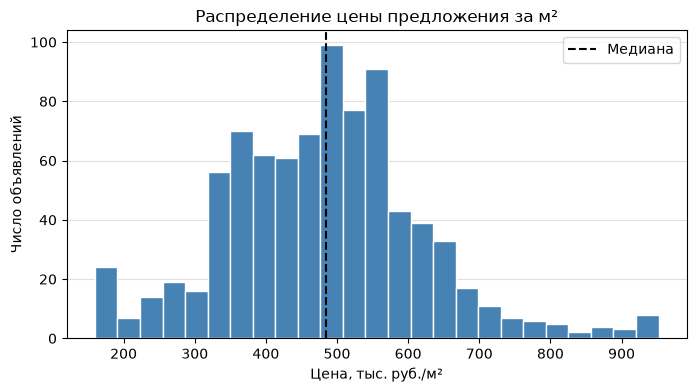

In [17]:
price_k = df["asking_price_per_m2_rub"] / 1_000

fig, ax = plt.subplots(figsize=(8, 4))
ax.hist(price_k, bins=25, color="steelblue", edgecolor="white")
ax.axvline(price_k.median(), color="black", linestyle="--", label="Медиана")
ax.set(
    title="Распределение цены предложения за м²",
    xlabel="Цена, тыс. руб./м²",
    ylabel="Число объявлений",
)
ax.legend()
ax.set_axisbelow(True)
ax.grid(axis="y", alpha=0.4)
plt.show()

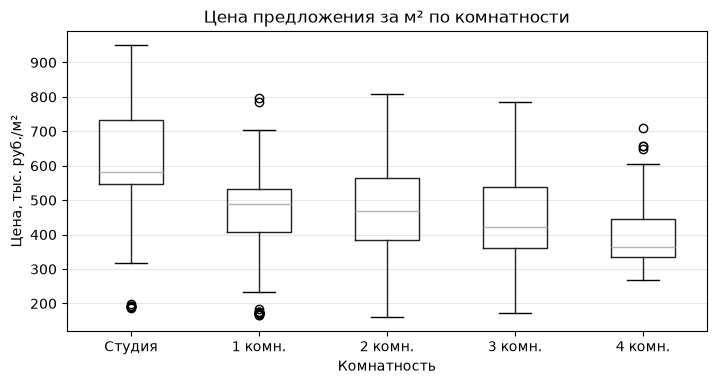

In [18]:
room_labels = ["Студия", "1 комн.", "2 комн.", "3 комн.", "4 комн."]

price_by_rooms = df.assign(
    price_k=price_k,
    rooms_label=pd.Categorical.from_codes(
        df["rooms"], categories=room_labels, ordered=True,
    ),
)

ax = price_by_rooms.boxplot(
    column="price_k", by="rooms_label", figsize=(8, 4), grid=False,
)
ax.figure.suptitle("")
ax.set(
    title="Цена предложения за м² по комнатности",
    xlabel="Комнатность",
    ylabel="Цена, тыс. руб./м²",
)
ax.set_axisbelow(True)
ax.grid(axis="y", alpha=0.3)
plt.show()

Медианная площадь квартиры — 45,3 м², медианная цена предложения -
484 528 руб./м². У центральной половины объявлений цена за м² находится
в диапазоне от 383 900 до 557 875 руб./м².

В этой выборке медианная цена за м² выше у ГК ФСК (520 229 руб./м²),
затем идут Level Group (495 071 руб./м²) и ПИК (382 450 руб./м²).
Это сравнение объявлений, а не сопоставимых квартир: у застройщиков
различаются состав ЖК, характеристики квартир и давность данных.

Медианная цена за м² снижается от студий (582 493 руб./м²)
к четырёхкомнатным квартирам (365 059 руб./м²), а медианная площадь
растёт с 28,5 до 91,5 м². Это наблюдение по всей выборке, без учёта
различий между ЖК и застройщиками. Четырёхкомнатных квартир всего 39.

## 5. Сохранение выборки

Сохраняем 843 проверенных объявления в отдельный CSV, не меняя входные
файлы. Оставляем целевую переменную `asking_price_per_m2_rub`,
группу ЖК `project_group` для разбиения, а также `source_url` и
`data_origin` для разбора объявлений. Наличие поля в CSV не означает,
что оно будет использоваться как признак модели.

In [19]:
output_path = data_dir / "processed" / "newbuild_prices_clean.csv"
output_path.parent.mkdir(parents=True, exist_ok=True)

df.to_csv(output_path, index=False)
print(f"Сохранено строк: {len(df)}. Файл: {output_path}")

Сохранено строк: 843. Файл: ../data/processed/newbuild_prices_clean.csv


In [20]:
saved = pd.read_csv(output_path, dtype=id_types)
print(f"В сохранённом CSV: {len(saved)} строк, {len(saved.columns)} столбца")

В сохранённом CSV: 843 строк, 24 столбца
